# 圆孔受压：实值 Kelvin 核 PIKFNN

与 `圆孔受压-KM-PIKFNN(2).ipynb` 对齐：平面应变；$a=1\,$m、$E=10^9\,$Pa、$\nu=0.3$、$p=10^6\,$Pa、外方框边长 $80a$；孔边 360 点、外边各 160 点，孔内 64 个源点、外边各 24 个源点；仅拟合边界条件，无内部 PDE 配点。输出网格与 KM 文件相同。

本对照用实值 Kelvin 张量 $U_{ij}=[-\kappa\ln r\,\delta_{ij}+r_i r_j/r^2]/[8\pi G(1-\nu)]$，其中 $r_i=x_i-s_i$、$\kappa=3-4\nu$。$u_i=\sum_m U_{ij}(x,s_m)F_{mj}+c_i+A_{ij}x_j$。应力由 $U_{ij}$ 的解析一阶导数及平面应变本构生成。常数和线性位移基保证与 KM 版本规则项相近，但两者参数化并非逐项相同。

默认 `AUTO_SOURCE=False` 固定与 KM 相同的源点，作为干净的核表示消融。设为 `True` 后，将在预设安全区间内用边界条件自动选择**两个整体几何尺度**（孔内源点环半径与外方框源点扩张比例），不是逐点自由移动；论文若报告此模式，应对 KM 基线实施同样的优化规则。这个算例的实值 Kelvin 核与 KM 点力核理论等价，因此不应预设 KM 在误差方面显著胜出。实值核层通过 PyTorch 的可训练参数和 Adam＋L-BFGS 优化；默认使用与 KM 笔记本相同类别的最小二乘初始化，也可关闭 `USE_LS_WARM_START` 从零开始训练。源点优化在误差接近浮点精度时没有唯一可辨识的最优位置。


In [1]:
import time
from pathlib import Path
import numpy as np
import scipy.linalg as la
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

a, L_out = 1.0, 80.0
E_real, nu, P0_real = 1.0e9, 0.3, 1.0e6
stress_scale = 1.0e6
E, P0 = E_real / stress_scale, P0_real / stress_scale
G = E / (2 * (1 + nu))
lam = E * nu / ((1 + nu) * (1 - 2 * nu))
kappa = 3 - 4 * nu

N_HOLE_SOURCES, N_SIDE_SOURCES = 64, 24
N_HOLE_BND, N_OUT_BND = 360, 160
HOLE_SOURCE_SCALE, OUTER_SOURCE_SCALE = 0.70, 1.20
AUTO_SOURCE = False
SOURCE_BOUNDS = ((0.45, 0.85), (1.08, 1.50))  # strictly off the domain
MAX_SOURCE_STEPS = 12
RIDGE = 0.0  # optional only for ill-conditioned systems; report if changed
USE_LS_WARM_START = True  # KM notebook also uses a least-squares warm start
ADAM_EPOCHS, LBFGS_MAX_ITER = 500, 1200
TRAIN_DTYPE = torch.float64  # preserve accuracy of the far-field kernel system

def build_sources(hole_scale=HOLE_SOURCE_SCALE, outer_scale=OUTER_SOURCE_SCALE):
    assert 0 < hole_scale < 1 and outer_scale > 1
    th = 2 * np.pi * np.arange(N_HOLE_SOURCES) / N_HOLE_SOURCES
    hole = hole_scale * a * np.column_stack((np.cos(th), np.sin(th)))
    h = 0.5 * L_out * outer_scale
    t = np.linspace(-h, h, N_SIDE_SOURCES + 2)[1:-1]
    sides = np.vstack((np.column_stack((t, np.full_like(t, -h))),
                       np.column_stack((np.full_like(t, h), t)),
                       np.column_stack((t[::-1], np.full_like(t, h))),
                       np.column_stack((np.full_like(t, -h), t[::-1]))))
    return np.vstack((hole, sides))

def boundary_points():
    th = 2 * np.pi * np.arange(N_HOLE_BND) / N_HOLE_BND
    hole = a * np.column_stack((np.cos(th), np.sin(th)))
    t = np.linspace(-L_out/2, L_out/2, N_OUT_BND+2)[1:-1]
    h = L_out/2
    outer = [np.column_stack((t, np.full_like(t,h))),
             np.column_stack((t, np.full_like(t,-h))),
             np.column_stack((np.full_like(t,h),t)),
             np.column_stack((np.full_like(t,-h),t))]
    return hole, outer

def exact_fields(points):
    x,y = points[:,0],points[:,1]
    r2=x*x+y*y
    factor=P0*a*a/r2
    ux=factor*x/(2*G); uy=factor*y/(2*G)
    sxx=factor*(1-2*x*x/r2)
    syy=factor*(1-2*y*y/r2)
    sxy=-2*factor*x*y/r2
    return ux,uy,sxx,syy,sxy

print(f'Plane strain; {N_HOLE_SOURCES+4*N_SIDE_SOURCES} sources; '
      f'{N_HOLE_BND+4*N_OUT_BND} boundary points; E*={E:g}, G*={G:.6g}')


Plane strain; 160 sources; 1000 boundary points; E*=1000, G*=384.615


In [2]:
def kelvin_features(points, sources):
    """Return five N x (2*M+6) design matrices in order ux,uy,sxx,syy,sxy.

Each source has two real Cartesian force coefficients. The final six columns
represent c_x,c_y,A_xx,A_xy,A_yx,A_yy of a compatible affine displacement.
All stresses use normalized stress units (MPa), displacements remain metres.
"""
    pts=np.asarray(points,dtype=np.float64).reshape(-1,2)
    src=np.asarray(sources,dtype=np.float64).reshape(-1,2)
    q=pts[:,None,:]-src[None,:,:]
    r2=np.sum(q*q,axis=2)
    if np.any(r2 < 1e-20):
        raise ValueError('A source intersects the evaluation region.')
    inv=1.0/r2
    n,m=r2.shape
    I=np.eye(2)
    C=1/(8*np.pi*G*(1-nu))
    # U[n,m,i,j]: displacement component i due to force component j.
    U=C*(-kappa*0.5*np.log(r2)[:,:,None,None]*I[None,None,:,:]
         + q[:,:,:,None]*q[:,:,None,:]*inv[:,:,None,None])
    # D[n,m,k,i,j] = derivative d(U_ij)/d(x_k).
    D=C*(-kappa*q[:,:, :,None,None]*inv[:,:,None,None,None]*I[None,None,None,:,:]
         + (I[None,None,:,: ,None]*q[:,:,None,None,:]
            +q[:,: ,None,:,None]*I[None,None,:,None,:])*inv[:,:,None,None,None]
         -2*q[:,:,:,None,None]*q[:,:,None,:,None]*q[:,:,None,None,:]
             *inv[:,:,None,None,None]**2)
    # Divergence for each force component j: sum_i dU_ij/dx_i.
    div=np.einsum('nmiij->nmj',D)
    dux_dx=D[:,:,0,0,:]; dux_dy=D[:,:,1,0,:]
    duy_dx=D[:,:,0,1,:]; duy_dy=D[:,:,1,1,:]
    stress_xx=lam*div+2*G*dux_dx
    stress_yy=lam*div+2*G*duy_dy
    stress_xy=G*(dux_dy+duy_dx)
    size=2*m+6
    mats=[np.zeros((n,size)) for _ in range(5)]
    for mat,feat in zip(mats,(U[:,:,0,:],U[:,:,1,:],stress_xx,stress_yy,stress_xy)):
        mat[:,:2*m]=feat.reshape(n,2*m)
    x,y=pts[:,0],pts[:,1]
    # c_x,c_y,A_xx,A_xy,A_yx,A_yy
    mats[0][:,2*m]=1; mats[0][:,2*m+2]=x; mats[0][:,2*m+3]=y
    mats[1][:,2*m+1]=1; mats[1][:,2*m+4]=x; mats[1][:,2*m+5]=y
    mats[2][:,2*m+2]=lam+2*G; mats[2][:,2*m+5]=lam
    mats[3][:,2*m+2]=lam; mats[3][:,2*m+5]=lam+2*G
    mats[4][:,2*m+3]=G; mats[4][:,2*m+4]=G
    return mats

def boundary_system(sources):
    hole,outer=boundary_points()
    ux,uy,sxx,syy,sxy=kelvin_features(hole,sources)
    ct=hole[:,0]/a; st=hole[:,1]/a
    rr=ct[:,None]**2*sxx+st[:,None]**2*syy+2*(ct*st)[:,None]*sxy
    rt=(ct*st)[:,None]*(syy-sxx)+(ct*ct-st*st)[:,None]*sxy
    blocks=[rr,rt]; targets=[np.full(hole.shape[0],-P0),np.zeros(hole.shape[0])]
    for side in outer:
        ux,uy,*_=kelvin_features(side,sources)
        tx,ty,*_=exact_fields(side)
        blocks.extend((2*G*ux,2*G*uy))
        targets.extend((2*G*tx,2*G*ty))
    return np.vstack(blocks),np.concatenate(targets)

def fit_sources(sources, ridge=RIDGE):
    A,b=boundary_system(sources)
    # Boundary objective matches the KM notebook: mean hole radial/shear
    # squared + sum over four sides of mean weighted ux/uy squared.
    nh,no=N_HOLE_BND,N_OUT_BND
    weights=np.concatenate((np.full(2*nh,1/np.sqrt(nh)),
                            np.full(8*no,1/np.sqrt(no))))
    Aw,bw=A*weights[:,None],b*weights
    if ridge:
        Aw=np.vstack((Aw,np.sqrt(ridge)*np.eye(A.shape[1])))
        bw=np.concatenate((bw,np.zeros(A.shape[1])))
    coeff,*_=la.lstsq(Aw,bw,lapack_driver='gelsy',check_finite=False)
    residual=(A@coeff-b)*weights
    return coeff,float(np.dot(residual,residual)),A,b

sources=build_sources()
assert sources.shape==(160,2)
print('Basis count:',2*len(sources)+6)


Basis count: 326


In [3]:
class KelvinPIKFNN(nn.Module):
    """Real Kelvin-kernel layer with two trainable force weights per source.

    Its basis matrix is fixed for a fixed source geometry. This is a linear
    physics-informed kernel network, not a generic multilayer perceptron.
    """
    def __init__(self, n_sources, initial=None):
        super().__init__()
        n_weights=2*n_sources+6
        if initial is None:
            w=torch.zeros(n_weights,dtype=TRAIN_DTYPE)
        else:
            w=torch.as_tensor(initial,dtype=TRAIN_DTYPE).clone()
        self.weights=nn.Parameter(w)

    def forward(self, features):
        return features@self.weights

start=time.perf_counter()
if AUTO_SOURCE:
    # Variable projection: solve the linear force coefficients for every
    # candidate geometry; optimize geometry using only the boundary conditions.
    # This is an optional joint source-placement experiment, not the fixed-source
    # Kelvin-vs-KM ablation. The two variables preserve symmetry and separation.
    _,base_loss,_,_=fit_sources(sources)
    if base_loss < 1e-12:
        print('WARNING: baseline boundary loss is near numerical precision; '
              'automatic source scales may not be identifiable on this case.')
    calls=[0]
    def objective(scales):
        calls[0]+=1
        _,val,_,_=fit_sources(build_sources(*scales))
        print(f'geometry solve {calls[0]}: hole={scales[0]:.4f}, '
              f'outer={scales[1]:.4f}, loss={val:.5e}')
        return val
    opt=minimize(objective,[HOLE_SOURCE_SCALE,OUTER_SOURCE_SCALE],
                 method='Powell',bounds=SOURCE_BOUNDS,
                 options={'maxiter':MAX_SOURCE_STEPS,'xtol':0.002,'ftol':0.001})
    candidate=np.asarray(opt.x)
    baseline=np.array([HOLE_SOURCE_SCALE,OUTER_SOURCE_SCALE])
    if objective(candidate)>objective(baseline):
        candidate=baseline
    sources=build_sources(*candidate)
    chosen_scales=tuple(candidate)
else:
    chosen_scales=(HOLE_SOURCE_SCALE,OUTER_SOURCE_SCALE)

ls_coeff,ls_loss,A_train,b_train=fit_sources(sources)
model=KelvinPIKFNN(len(sources),ls_coeff if USE_LS_WARM_START else None)
nh,no=N_HOLE_BND,N_OUT_BND
weights=np.concatenate((np.full(2*nh,1/np.sqrt(nh)),
                        np.full(8*no,1/np.sqrt(no))))
A_t=torch.from_numpy(A_train*weights[:,None]).to(TRAIN_DTYPE)
b_t=torch.from_numpy(b_train*weights).to(TRAIN_DTYPE)

def loss_fn():
    residual=model(A_t)-b_t
    loss=torch.dot(residual,residual)
    if RIDGE:
        loss=loss+RIDGE*torch.dot(model.weights,model.weights)
    return loss

adam=torch.optim.Adam(model.parameters(),lr=5e-4)
for epoch in range(ADAM_EPOCHS):
    adam.zero_grad()
    loss=loss_fn()
    loss.backward()
    adam.step()
    if epoch%100==0 or epoch==ADAM_EPOCHS-1:
        print(f'Adam {epoch:4d} | boundary loss {loss.item():.6e}')

lbfgs=torch.optim.LBFGS(model.parameters(),lr=1.0,
    max_iter=LBFGS_MAX_ITER,max_eval=int(LBFGS_MAX_ITER*1.5)+1,
    history_size=100,tolerance_grad=1e-9,tolerance_change=1e-11,
    line_search_fn='strong_wolfe')
def closure():
    lbfgs.zero_grad()
    loss=loss_fn()
    loss.backward()
    return loss
lbfgs.step(closure)
coeff=model.weights.detach().cpu().numpy().copy()
final_loss=float(loss_fn().detach().cpu().item())
PIKFNN_TRAIN_TIME=time.perf_counter()-start
residual=A_train@coeff-b_train
print(f'Source scales (inner, outer): {chosen_scales}')
print(f'Kelvin PIKFNN boundary loss: {final_loss:.6e}; '
      f'boundary residual RMS: {np.sqrt(np.mean(residual**2)):.6e}')
print(f'LS initialization + Adam + L-BFGS training: {PIKFNN_TRAIN_TIME:.2f} s')

def predict(points, chunk=2048):
    points=np.asarray(points,dtype=float).reshape(-1,2)
    parts=[]
    for offset in range(0,len(points),chunk):
        mats=kelvin_features(points[offset:offset+chunk],sources)
        parts.append(np.column_stack([M@coeff for M in mats]))
    return np.vstack(parts)

# Independent reference and boundary diagnostics (same analytical field as
# the other notebooks; these values are NOT used to choose source locations).
phi=2*np.pi*(np.arange(720)+0.5)/720
check=np.column_stack((a*np.cos(phi),a*np.sin(phi)))
u,v,sxx,syy,sxy=predict(check).T
ct,st=np.cos(phi),np.sin(phi)
rr=sxx*ct**2+syy*st**2+2*sxy*ct*st
rt=(syy-sxx)*ct*st+sxy*(ct**2-st**2)
print('Holdout hole BC RMS (MPa):',np.sqrt(np.mean((rr+P0)**2+rt**2)))


Adam    0 | boundary loss 1.122346e-16
Adam  100 | boundary loss 7.121126e-03
Adam  200 | boundary loss 3.780591e-06
Adam  300 | boundary loss 1.794013e-06
Adam  400 | boundary loss 1.204417e-06
Adam  499 | boundary loss 8.133357e-07
Source scales (inner, outer): (0.7, 1.2)
Kelvin PIKFNN boundary loss: 8.100723e-07; boundary residual RMS: 3.592567e-04
LS initialization + Adam + L-BFGS training: 1.85 s
Holdout hole BC RMS (MPa): 0.0008016207599177849


Analytical relative L2 Ux: 1.306987e-03
Analytical relative L2 Uy: 1.221687e-03
Analytical relative L2 von Mises: 4.361925e-04


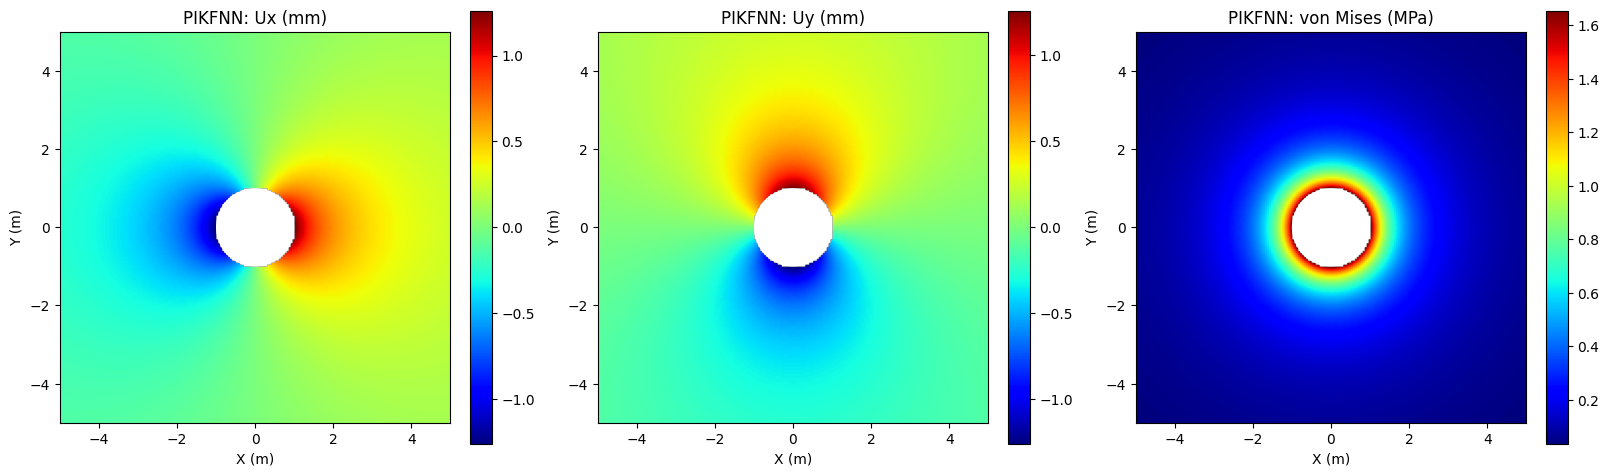

In [4]:
# Same 200x200, [-5a,5a]^2 evaluation grid and r>=1.02a mask as KM.
L_plot,grid_size=5*a,200
axis=np.linspace(-L_plot,L_plot,grid_size)
XX,YY=np.meshgrid(axis,axis)
valid_mask=np.hypot(XX,YY)>=1.02*a
pts=np.column_stack((XX[valid_mask],YY[valid_mask]))
pred=predict(pts)
ref=np.column_stack(exact_fields(pts))
names=['Ux','Uy','von Mises']

def von_mises(fields):
    sx,sy,txy=fields[:,2],fields[:,3],fields[:,4]
    sz=nu*(sx+sy)
    return np.sqrt(((sx-sy)**2+(sy-sz)**2+(sz-sx)**2)/2+3*txy**2)

vm=von_mises(pred); vm_ref=von_mises(ref)
for name,approx,truth in zip(names,(pred[:,0],pred[:,1],vm),
                             (ref[:,0],ref[:,1],vm_ref)):
    print(f'Analytical relative L2 {name}: '
          f'{np.linalg.norm(approx-truth)/np.linalg.norm(truth):.6e}')

fig,axes=plt.subplots(1,3,figsize=(16,4.7),constrained_layout=True)
for ax,values,title,unit in zip(axes,(pred[:,0]*1e3,pred[:,1]*1e3,vm),
                                ('Ux','Uy','von Mises'),('mm','mm','MPa')):
    full=np.full(XX.shape,np.nan); full[valid_mask]=values
    im=ax.imshow(full,extent=(-L_plot,L_plot,-L_plot,L_plot),origin='lower',cmap='jet')
    ax.add_patch(plt.Circle((0,0),a,facecolor='white'))
    ax.set(xlabel='X (m)',ylabel='Y (m)',title=f'PIKFNN: {title} ({unit})')
    fig.colorbar(im,ax=ax)
plt.show()


In [5]:
# SI-unit export compatible with the existing bem_fields.npz,
# pinn_fields.npz, and km_pikfnn_fields.npz evaluation scheme.
def to_map(values,unit_scale=1):
    out=np.full(XX.shape,np.nan)
    out[valid_mask]=values*unit_scale
    return out

result_dir=Path.cwd()/'field_results'
result_dir.mkdir(parents=True,exist_ok=True)
output_file=result_dir/'pikfnn_kelvin_fields.npz'
maps={name:to_map(values,scale) for name,values,scale in
      [('ux',pred[:,0],1),('uy',pred[:,1],1),
       ('sxx',pred[:,2],stress_scale),('syy',pred[:,3],stress_scale),
       ('sxy',pred[:,4],stress_scale),('vm',vm,stress_scale)]}
np.savez_compressed(output_file,X=XX,Y=YY,valid_mask=valid_mask,
                    **maps,a=a,L_plot=L_plot,grid_size=grid_size,
                    displacement_unit='m',stress_unit='Pa',method='PIKFNN-Kelvin',
                    trainable_parameters=len(coeff),training_time_s=PIKFNN_TRAIN_TIME,
                    final_loss=final_loss,source_count=len(sources),
                    hole_source_count=N_HOLE_SOURCES,
                    outer_source_count=len(sources)-N_HOLE_SOURCES,
                    auto_source=AUTO_SOURCE,source_scales=np.array(chosen_scales))
print('Saved:',output_file.resolve())

bem_path=result_dir/'bem_fields.npz'
if bem_path.exists():
    with np.load(bem_path) as bem:
        if not (np.array_equal(bem['X'],XX) and np.array_equal(bem['Y'],YY)):
            raise ValueError('BEM grid does not match the PIKFNN grid.')
        common=valid_mask & np.asarray(bem['valid_mask'],bool)
        for key in ('ux','uy','vm'):
            truth=np.asarray(bem[key])[common]
            estimate=maps[key][common]
            print(f'BEM relative L2 {key}: '
                  f'{np.linalg.norm(estimate-truth)/np.linalg.norm(truth):.6e}')
else:
    print('BEM snapshot absent. Run the BEM notebook export cell and rerun this cell for BEM errors.')


Saved: C:\Users\magic\Desktop\KM-PIKFNN\圆孔受压\field_results\pikfnn_kelvin_fields.npz
BEM relative L2 ux: 3.065525e-03
BEM relative L2 uy: 3.306516e-03
BEM relative L2 vm: 6.099467e-03
